# Romanized Telugu–English Film Review Sentiment Classification
### SimpleRNN vs LSTM vs GRU · Scratch vs English-IMDB transfer · Team 6 · Task 2B

**Read this first (honest status).**

- **Data is SYNTHETIC.** The 6,000 labelled reviews are generated by a clause-template grammar written in Romanized Telugu (Telugu in Latin letters) mixed with English. Labels come from generation rules, **not** from human annotators. Results describe performance on this synthetic corpus only and do not establish real-world performance.
- **No human annotation was performed.** Therefore inter-annotator agreement was **not** measured. Cohen's Kappa reported here is model-versus-rule-label agreement only.
- **Strategy B (English transfer)** uses the Keras IMDB dataset when it can be downloaded; otherwise it falls back to the IMDb-sourced Pang & Lee polarity corpus (2,000 English reviews) and says so. The source actually used is printed and recorded in `config.json`.
- Model selection uses **validation data only** (average of in-distribution validation Macro F1 and unseen-data validation Macro F1). The test sets are evaluated once, after all selection decisions are fixed.
- **Unseen-data robustness** is tested on a separate challenge set in which every review contains tokens never seen in training (Section 9b). The slang/English novel lexicon was written without native-speaker review.
- The final checklist (Section 18) marks each assignment requirement as ACHIEVED, NOT ACHIEVED, INCOMPLETE, or NOT APPLICABLE based on what the run actually produced.


## 1. Environment and reproducibility

In [1]:
import os, re, json, time, random, pickle, zipfile, unicodedata, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, cohen_kappa_score)
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

LABELS = ["Positive", "Negative", "Mixed"]
N_PER_CLASS = 2000            # labelled synthetic reviews per class
BENCH_COUNTS = {"Positive": 3334, "Negative": 3333, "Mixed": 3333}   # 10,000 distinct CPU-benchmark reviews
EMBED_DIM = 48
RNN_UNITS = 64
BATCH_SIZE = 32
EPOCHS = 12
PATIENCE = 2
LR = 1e-3
SEQ_LEN_CANDIDATES = [64, 128, 192, 256]
MODEL_TYPES = ["SimpleRNN", "LSTM", "GRU"]
FINAL_SEEDS = [42, 43, 44]
ARTIFACT_DIR = Path("DL_T06_2B")
ARTIFACT_DIR.mkdir(exist_ok=True)
CACHE_DIR = Path("model_cache")      # lets an interrupted run resume without retraining
CACHE_DIR.mkdir(exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Python:", platform.python_version(), "| Machine:", platform.machine())
print("Devices:", [d.name for d in tf.config.list_physical_devices()])
print("CPU count:", os.cpu_count())

I0000 00:00:1793460169.762049     100 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793460183.697296     100 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793460190.271144     100 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0
Python: 3.12.3 | Machine: x86_64
Devices: ['/physical_device:CPU:0']
CPU count: 1


## 2. Generate the labelled Romanized Telugu–English corpus (SYNTHETIC)

Reviews are composed from **opinion clauses** (aspect + evaluative phrase) with a known polarity, and then passed through **spelling-variation noise**. The generator deliberately includes the phenomena named in the assignment:

| Pattern | Label rule | Purpose |
|---|---|---|
| `pos_only` | only positive clauses (some negated, e.g. "boring ga ledu") | positive class; negation |
| `neg_only` | only negative clauses (some with "nachaledu", "baaledu") | negative class |
| `sarcasm` | negative verdict expressed with a positive word ("super ga undi, nidra vachesindi") | sarcasm errors |
| `contrast` | one positive and one negative clause joined by kani / but / ayithe | Mixed |
| `long_tail` | praise, 2–4 neutral filler sentences, then a final complaint after "kani" | long-range context; 30% place the complaint first and the praise last |
| `hedge` | a hedge positive ("konchem bagundi") with two negative clauses | Mixed, flagged ambiguous |

The Telugu-script characters are **not** used anywhere in this corpus. All text is Latin-script Romanized Telugu with English words.

In [2]:
ASPECTS = ["acting", "story", "screenplay", "direction", "music", "songs", "visuals", "cinematography",
           "climax", "comedy", "dialogues", "editing", "first half", "second half", "vfx", "emotions",
           "hero performance", "heroine role", "background score", "ending", "action scenes",
           "twists", "narration", "fight scenes", "villain", "pace"]
MOVIES = ["Vanthara", "Nagaram Nidra", "Veera Dhaara", "Chandrika Kotha", "Sagara Theeram",
          "Gaali Mahal", "Thoofan Nagar", "Nelaparu Raju"]          # fictional titles

POS_CLAUSES = ["{A} chala bagundi", "{A} super ga undi", "{A} excellent ga undi", "{A} baagundi",
               "{A} bagundhi", "{A} adirindi", "{A} mind blowing ga undi", "{A} highlight ga nilichindi",
               "{A} heart touching ga undi", "{A} engaging ga undi", "{A} perfect ga set ayyindi",
               "{A} entertaining ga undi", "{A} strong ga undi", "{A} awesome ga undi", "{A} bagunnayi"]
NEG_CLAUSES = ["{A} chala boring ga undi", "{A} slow ga undi", "{A} weak ga undi", "{A} baaledu",
               "{A} nachaledu", "{A} bagaledu", "{A} disappointing ga undi", "{A} confusing ga undi",
               "{A} annoying ga undi", "{A} lag avtundi", "{A} ki connect avvaledu", "{A} poor ga undi",
               "{A} artificial ga undi", "{A} irritating ga undi", "{A} messy ga undi", "{A} predictable ga undi"]
POS_NEGATED = ["{A} boring ga ledu", "{A} slow ga ledu", "{A} weak ga ledu", "{A} lo lopam ledu",
               "{A} bore kottaledu"]
SARCASM = ["{A} super ga undi, nidra vachesindi", "{A} excellent ga undi, bore kottindi"]
POS_STANDALONE = ["movie must watch", "paisa vasool cinema", "family ki nachutundi",
                  "theatre lo chudandi", "definitely recommended"]
NEG_STANDALONE = ["time waste movie", "paisa waste", "avoid cheyandi", "not recommended",
                  "cinema assalu nachaledu", "waste of money", "regret ayyanu"]
HEDGE_POS = ["konchem bagundi", "konchem bagundi anipinchindi"]
FILLERS = ["{M} trailer chusi theatre ki vellanu", "friends tho kalisi chusam",
           "{M} kosam chala waiting chesam", "runtime around 150 minutes", "weekend lo chusanu",
           "{M} lo {A} gurinchi cheppali", "intermission tarvata katha maarutundi",
           "ticket rates kuda normal ga unnay", "{M} story setting lo jarugutundi",
           "ee review naa vyaktigata opinion"]
CONNECT_MIXED = [" kani ", " kaani ", " but ", " ayithe "]
JOINERS = [", ", " and ", " mariyu ", ". "]

# Spelling-variation table: canonical form -> plausible Romanized variants.
SPELL = {"chala": ["chaala", "chalaa"], "bagundi": ["baagundi", "bagundhi"],
         "baaledu": ["baledu", "balledu"], "nachaledu": ["nachaledhu"], "undi": ["undhi"],
         "adirindi": ["adirindhi"], "avvaledu": ["avaledu"]}
SPELL_RE = re.compile(r"\b(" + "|".join(sorted(SPELL, key=len, reverse=True)) + r")\b")
# Negation detector: any token ending in ledu/ledhu/kaadu/kaadhu (covers baaledu, nachaledu, ga ledu, ...)
NEGATION_RE = re.compile(r"\b\w*(ledu|ledhu|kaadu|kaadhu)\b")


def fill(rng):
    return rng.choice(FILLERS).format(M=rng.choice(MOVIES), A=rng.choice(ASPECTS))


def opinion(rng, sign):
    A = rng.choice(ASPECTS)
    if sign == "pos":
        pool = POS_NEGATED if rng.random() < 0.15 else POS_CLAUSES
    elif sign == "neg":
        pool = NEG_CLAUSES
    else:
        pool = SARCASM
    return rng.choice(pool).format(A=A), A


def standalone(rng, sign):
    pool = POS_STANDALONE if sign == "pos" else NEG_STANDALONE
    return rng.choice(pool), None


def add_spelling_noise(text, rng):
    changed = [False]
    def repl(m):
        if rng.random() < 0.6:
            changed[0] = True
            return rng.choice(SPELL[m.group(0)])
        return m.group(0)
    out = SPELL_RE.sub(repl, text)
    if rng.random() < 0.04 and re.search(r"\bchala\b", out):
        out = re.sub(r"\bchala\b", "chalaaaa", out, count=1)   # rare elongated, unseen form
        changed[0] = True
    return out, changed[0]


def make_review(label, rng):
    flags = {"sarcasm": 0, "hedge_ambiguous": 0, "long_tail": 0, "long_form": 0, "tail_complaint": 0}
    parts, aspects = [], []
    if label == "Positive":
        pattern = "pos_only"
        for _ in range(rng.choice([1, 2, 2, 3, 3, 4])):
            t, a = standalone(rng, "pos") if rng.random() < 0.12 else opinion(rng, "pos")
            parts.append(t); aspects.append(a)
    elif label == "Negative":
        pattern = "neg_only"
        for _ in range(rng.choice([1, 2, 2, 3, 3, 4])):
            t, a = standalone(rng, "neg") if rng.random() < 0.12 else opinion(rng, "neg")
            parts.append(t); aspects.append(a)
        if rng.random() < 0.15:
            pattern = "sarcasm"; flags["sarcasm"] = 1
            t, a = opinion(rng, "sarcasm"); parts.append(t); aspects.append(a)
    else:
        r = rng.random()
        if r < 0.40:
            pattern = "contrast"
            pt, pa = opinion(rng, "pos"); nt, na = opinion(rng, "neg")
            conn = rng.choice(CONNECT_MIXED)
            parts = [pt + conn + nt] if rng.random() < 0.5 else [nt + conn + pt]
            aspects = [pa]
        elif r < 0.80:
            pattern = "long_tail"; flags["long_tail"] = 1
            pt, pa = opinion(rng, "pos"); nt, na = opinion(rng, "neg")
            pads = [fill(rng) for _ in range(rng.choice([4, 8, 12, 18]))]
            padtxt = " ".join(p + "." for p in pads)
            if rng.random() < 0.7:      # praise first, complaint LAST (complaint at the tail)
                parts = [pt + ". " + padtxt + " kani " + nt]
                flags["tail_complaint"] = 1
            else:                       # complaint first, praise last
                parts = [nt + ". " + padtxt + " kani " + pt]
            flags["long_form"] = 1
            aspects = [pa]
        else:
            pattern = "hedge"; flags["hedge_ambiguous"] = 1
            n1, a1 = opinion(rng, "neg"); n2, a2 = opinion(rng, "neg")
            parts = [rng.choice(HEDGE_POS) + " kani " + n1 + rng.choice([", ", " and "]) + n2]
            aspects = [a1]

    text = parts[0] if len(parts) == 1 else ""
    if len(parts) > 1:
        text = parts[0]
        for p in parts[1:]:
            text += rng.choice(JOINERS) + p
    if label in ("Positive", "Negative") and rng.random() < 0.35:
        pads = " ".join(fill(rng) + "." for _ in range(rng.choice([4, 8, 12, 18])))
        first, _, rest = text.partition(", ")
        text = first + ". " + pads + (" " + rest if rest else "")
        flags["long_form"] = 1
    if pattern != "long_tail" and rng.random() < 0.35:
        text = fill(rng) + ", " + text            # opening neutral sentence
    if pattern != "long_tail" and rng.random() < 0.15:
        text = text + ". " + fill(rng)            # closing neutral sentence (not after a long-tail complaint)

    text, spelled = add_spelling_noise(text, rng)
    if rng.random() < 0.5:
        text = text[0].upper() + text[1:]
    text = text + rng.choice(["", "", ".", "!"])

    primary = aspects[0] if aspects and aspects[0] else "none"
    meta = {"pattern": pattern, "primary_aspect": primary,
            "group_id": f"{label}|{pattern}|{primary}",
            "spelling_variant": int(spelled),
            "negation": int(bool(NEGATION_RE.search(text.lower())))}
    meta.update(flags)
    return text, meta


def generate(counts, seed, exclude=()):
    rng = random.Random(seed)
    seen = set(exclude)
    remaining = dict(counts)
    rows = []
    while sum(remaining.values()) > 0:
        label = rng.choice([l for l in LABELS if remaining[l] > 0])
        text, meta = make_review(label, rng)
        if text in seen:
            continue
        seen.add(text)
        remaining[label] -= 1
        rows.append({"review": text, "sentiment": label, **meta})
    return pd.DataFrame(rows)


df = generate({l: N_PER_CLASS for l in LABELS}, seed=SEED)
df.insert(0, "review_id", [f"TE{i:05d}" for i in range(len(df))])
bench_df = generate(BENCH_COUNTS, seed=SEED + 1000, exclude=set(df.review))
bench_df.insert(0, "review_id", [f"BN{i:05d}" for i in range(len(bench_df))])

assert df.review.is_unique and bench_df.review.is_unique
assert set(df.review).isdisjoint(set(bench_df.review))
assert df.sentiment.value_counts().to_dict() == {l: N_PER_CLASS for l in LABELS}
assert len(bench_df) == 10000

df.to_csv(ARTIFACT_DIR / "telugu_romanized_labelled_SYNTHETIC.csv", index=False, encoding="utf-8-sig")
bench_df[["review_id", "review", "sentiment"]].to_csv(
    ARTIFACT_DIR / "cpu_benchmark_pool_10000_SYNTHETIC.csv", index=False, encoding="utf-8-sig")

print("Labelled rows:", len(df), "| benchmark pool rows:", len(bench_df))
print("Telugu-script characters in corpus:",
      int(df.review.str.contains(r"[\u0C00-\u0C7F]").sum()))
display(df.head(8)[["review", "sentiment", "pattern"]])

Labelled rows: 6000 | benchmark pool rows: 10000
Telugu-script characters in corpus: 0


,review,sentiment,pattern
0,"friends tho kalisi chusam, music baledu kani f...",Mixed,contrast
1,"weekend lo chusanu, pace strong ga undhi. narr...",Positive,pos_only
2,villain lag avtundi kani screenplay slow ga ledu,Mixed,contrast
3,Climax weak ga undhi. songs confusing ga undi....,Negative,neg_only
4,Chandrika Kotha trailer chusi theatre ki vella...,Positive,pos_only
5,narration bagundhi. ee review naa vyaktigata o...,Positive,pos_only
6,"Pace baagundi, heroine role mind blowing ga un...",Positive,pos_only
7,Story bagaledu. first half annoying ga undhi. ...,Negative,neg_only


## 3. Dataset inspection and data card statistics

Missing values: 0
Duplicate review texts: 0
Distinct groups: 159


,count
sentiment,
Positive,2000
Negative,2000
Mixed,2000


sentiment,Mixed,Negative,Positive
pattern,,,
contrast,800,0,0
hedge,429,0,0
long_tail,771,0,0
neg_only,0,1677,0
pos_only,0,0,2000
sarcasm,0,323,0


,reviews_with_flag
negation,2315
spelling_variant,4621
sarcasm,323
hedge_ambiguous,429
long_tail,771
long_form,2144
tail_complaint,541


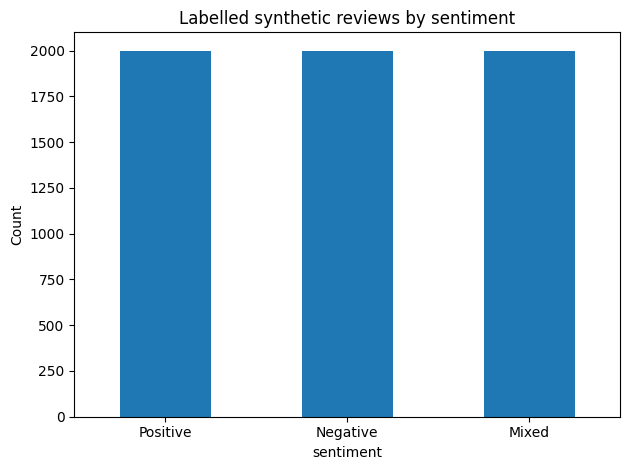

In [3]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate review texts:", int(df.review.duplicated().sum()))
print("Distinct groups:", df.group_id.nunique())
display(df.sentiment.value_counts().reindex(LABELS).to_frame("count"))
display(pd.crosstab(df.pattern, df.sentiment))
flag_cols = ["negation", "spelling_variant", "sarcasm", "hedge_ambiguous", "long_tail", "long_form", "tail_complaint"]
display(df[flag_cols].sum().to_frame("reviews_with_flag"))

ax = df.sentiment.value_counts().reindex(LABELS).plot(kind="bar", rot=0)
ax.set_title("Labelled synthetic reviews by sentiment"); ax.set_ylabel("Count")
plt.tight_layout(); plt.show()

## 4. Preprocessing (Romanized-Telugu-safe)

Text is lower-cased, Unicode-normalised, and punctuation is separated into its own token. Letters, combining marks, digits, and sentence punctuation are kept. Romanized Telugu words (e.g. *chala*, *bagundi*, *baaledu*, *nachaledu*) and English words are **not** removed, because they are not English dictionary words. Negation tokens are checked explicitly after cleaning.

In [4]:
def clean_text(text):
    text = unicodedata.normalize("NFC", str(text)).lower()
    text = re.sub(r"([.,!?])", r" \1 ", text)
    kept = []
    for ch in text:
        cat = unicodedata.category(ch)
        kept.append(ch if (cat[0] in {"L", "M", "N"} or ch.isspace() or ch in ".,!?'") else " ")
    return re.sub(r"\s+", " ", "".join(kept)).strip()


probe = "Movie chala bagundi, kani climax boring ga undi. Acting nachaledu!"
cleaned_probe = clean_text(probe)
print("Original:", probe)
print("Cleaned :", cleaned_probe)
for token in ["chala", "bagundi", "kani", "boring", "nachaledu"]:
    assert token in cleaned_probe.split(), f"token lost: {token}"
print("PASS: Romanized Telugu and English sentiment tokens preserved.")

df["clean_review"] = df.review.map(clean_text)
assert df.clean_review.str.len().gt(0).all()
neg_before = int(df.negation.sum())
neg_after = int(df.clean_review.map(lambda s: bool(NEGATION_RE.search(s))).sum())
assert neg_before == neg_after, "Cleaning changed negation-bearing reviews"
print(f"PASS: negation-bearing reviews unchanged by cleaning ({neg_after}).")
df["n_tokens"] = df.clean_review.str.split().map(len)
display(df.n_tokens.describe().to_frame("tokens_per_review"))

Original: Movie chala bagundi, kani climax boring ga undi. Acting nachaledu!
Cleaned : movie chala bagundi , kani climax boring ga undi . acting nachaledu !
PASS: Romanized Telugu and English sentiment tokens preserved.


PASS: negation-bearing reviews unchanged by cleaning (2315).


,tokens_per_review
count,6000.000000
mean,36.980167
std,36.088135
min,2.000000
25%,12.000000
50%,19.000000
75%,57.000000
max,152.000000


## 5. Group-aware train / validation / test split

Reviews are grouped by `(label, pattern, primary aspect)`. Each group is assigned wholly to one split, with about 70% / 15% / 15% of reviews per class. This prevents near-duplicate construction patterns from leaking between splits.

In [5]:
def group_split(frame, seed):
    rng = np.random.default_rng(seed)
    split = pd.Series(index=frame.index, dtype=object)
    for label in LABELS:
        sub = frame[frame.sentiment == label]
        groups = sub.group_id.unique().tolist()
        rng.shuffle(groups)
        total = len(sub); cum = 0; assign = {}
        for g in groups:
            n = int((sub.group_id == g).sum())
            if cum < 0.70 * total:
                assign[g] = "train"
            elif cum < 0.85 * total:
                assign[g] = "validation"
            else:
                assign[g] = "test"
            cum += n
        split.loc[sub.index] = sub.group_id.map(assign)
    return split


df["split"] = group_split(df, SEED)
train_df = df[df.split == "train"].copy()
val_df = df[df.split == "validation"].copy()
test_df = df[df.split == "test"].copy()

for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert set(a.group_id).isdisjoint(set(b.group_id)), "group leakage"
for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{name:10s} n={len(part):5d}", part.sentiment.value_counts().reindex(LABELS).to_dict())
    assert set(part.sentiment) == set(LABELS), f"{name} lacks a class"
print("PASS: no group overlap; every split contains all three classes.")

train      n= 4274 {'Positive': 1407, 'Negative': 1452, 'Mixed': 1415}
validation n=  897 {'Positive': 340, 'Negative': 248, 'Mixed': 309}
test       n=  829 {'Positive': 253, 'Negative': 300, 'Mixed': 276}
PASS: no group overlap; every split contains all three classes.


## 6. Vocabulary fitted on training data only

The tokenizer is fitted on training reviews only. Out-of-vocabulary (unseen) rates are measured on validation and test to quantify the *unseen vocabulary* effect used later in error analysis.

In [6]:
tokenizer = Tokenizer(oov_token="<OOV>", filters="", lower=True)
tokenizer.fit_on_texts(train_df.clean_review)
TRAIN_VOCAB = set(tokenizer.word_index) - {"<OOV>"}
VOCAB_SIZE = len(tokenizer.word_index) + 1
print("Vocabulary size (incl. padding + OOV):", VOCAB_SIZE)

def oov_stats(part):
    toks = [t for s in part.clean_review for t in s.split()]
    oov_tok = sum(t not in TRAIN_VOCAB for t in toks) / len(toks)
    rev_with = part.clean_review.map(lambda s: any(t not in TRAIN_VOCAB for t in s.split())).mean()
    return oov_tok, rev_with

for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    tok_rate, rev_rate = oov_stats(part)
    print(f"{name:10s} token OOV rate = {tok_rate:.4f} | reviews with >=1 unseen token = {rev_rate:.3f}")

Vocabulary size (incl. padding + OOV): 173


train      token OOV rate = 0.0000 | reviews with >=1 unseen token = 0.000
validation token OOV rate = 0.0000 | reviews with >=1 unseen token = 0.000
test       token OOV rate = 0.0000 | reviews with >=1 unseen token = 0.000


## 7. Sequence-length experiment

**Pre-declared rule (fixed before running):** evaluate candidate lengths 64, 128, 192, 256. For each length, train all three architectures with seed 42 using validation data only. Select the length that maximises the **mean validation Macro F1** over the three architectures. Ties go to the shorter length. Test data is not used.

Two measures explain the trade-off. *Truncation rate* is the share of training reviews longer than L (post-truncation drops the **end** of the review). *Tail-complaint retention* is the share of long-tail reviews whose final complaint survives truncation.

In [7]:
def make_X(texts, L):
    return pad_sequences(tokenizer.texts_to_sequences(texts), maxlen=L, padding="post", truncating="post")

def build_model(model_type, vocab_size, max_len, n_out=3, loss_name="sparse_categorical_crossentropy"):
    layer = {"SimpleRNN": SimpleRNN, "LSTM": LSTM, "GRU": GRU}[model_type]
    head_act = "softmax" if n_out == 3 else "sigmoid"
    model = Sequential([
        Input(shape=(max_len,)),
        Embedding(input_dim=vocab_size, output_dim=EMBED_DIM, mask_zero=True, name="embedding"),
        layer(RNN_UNITS, dropout=0.2, name="recurrent"),
        Dense(24, activation="relu", name="hidden_dense"),
        Dropout(0.2),
        Dense(n_out, activation=head_act, name="output"),
    ], name=f"{model_type}_{n_out}out")
    model.compile(optimizer=tf.keras.optimizers.Adam(LR), loss=loss_name, metrics=["accuracy"])
    return model

def train_model(model_type, seed, X_tr, y_tr, X_va, y_va, vocab_size, max_len, init_fn=None, tag="scratch"):
    key = f"{tag}_{model_type}_L{max_len}_s{seed}"
    mpath, jpath = CACHE_DIR / f"{key}.keras", CACHE_DIR / f"{key}.json"
    if mpath.exists() and jpath.exists():                      # resume: reuse an already-trained identical run
        meta = json.load(open(jpath))
        return tf.keras.models.load_model(mpath), {"loss": [0.0] * meta["epochs"]}, meta["seconds"]
    tf.keras.utils.set_random_seed(seed)
    model = build_model(model_type, vocab_size, max_len)
    if init_fn is not None:
        init_fn(model)
    es = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    t0 = time.perf_counter()
    hist = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=EPOCHS,
                     batch_size=BATCH_SIZE, callbacks=[es], verbose=0, shuffle=True)
    train_seconds = time.perf_counter() - t0
    model.save(mpath)
    json.dump({"epochs": len(hist.history["loss"]), "seconds": train_seconds}, open(jpath, "w"))
    return model, hist.history, train_seconds

label_encoder = LabelEncoder().fit(LABELS)
MIXED_ID = int(label_encoder.transform(["Mixed"])[0])
y_train = label_encoder.transform(train_df.sentiment)
y_val = label_encoder.transform(val_df.sentiment)
y_test = label_encoder.transform(test_df.sentiment)
print("Label ids:", dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

seq_rows = []
for L in SEQ_LEN_CANDIDATES:
    trunc_rate = float((train_df.n_tokens > L).mean())
    tails = df[df.tail_complaint == 1]
    tail_kept = float((tails.n_tokens <= L).mean())
    seq_rows.append({"Max length": L,
                     "Train truncated (%)": round(100 * trunc_rate, 2),
                     "Final complaint retained (%)": round(100 * tail_kept, 2)})
seq_stats = pd.DataFrame(seq_rows)
display(seq_stats)

Label ids: {np.str_('Mixed'): np.int64(0), np.str_('Negative'): np.int64(1), np.str_('Positive'): np.int64(2)}


,Max length,Train truncated (%),Final complaint retained (%)
0,64,21.08,51.02
1,128,1.80,99.26
2,192,0.00,100.00
3,256,0.00,100.00


In [8]:
sweep_rows = []
for L in SEQ_LEN_CANDIDATES:
    X_tr = make_X(train_df.clean_review, L)
    X_va = make_X(val_df.clean_review, L)
    for mt in MODEL_TYPES:
        t_start = time.perf_counter()
        model, hist, secs = train_model(mt, SEED, X_tr, y_train, X_va, y_val, VOCAB_SIZE, L)
        pred = model.predict(X_va, verbose=0).argmax(axis=1)
        sweep_rows.append({"Max length": L, "Model": mt,
                           "Val Macro F1": f1_score(y_val, pred, average="macro", zero_division=0),
                           "Val Mixed F1": f1_score(y_val, pred, labels=[MIXED_ID], average=None, zero_division=0)[0],
                           "Epochs run": len(hist["loss"]), "Train seconds": round(secs, 1)})
        print(f"L={L:3d} {mt:9s} val Macro F1={sweep_rows[-1]['Val Macro F1']:.4f} epochs={len(hist['loss'])} ({secs:.0f}s)")

sweep_df = pd.DataFrame(sweep_rows)
sweep_summary = (sweep_df.groupby("Max length")[["Val Macro F1", "Val Mixed F1"]]
                 .mean().reset_index().rename(columns={"Val Macro F1": "Mean val Macro F1",
                                                       "Val Mixed F1": "Mean val Mixed F1"}))
sweep_summary = sweep_summary.merge(seq_stats, on="Max length")
sweep_summary = sweep_summary.sort_values(["Mean val Macro F1", "Max length"], ascending=[False, True]).reset_index(drop=True)
display(sweep_df)
display(sweep_summary)

MAX_LEN = int(sweep_summary.iloc[0]["Max length"])
print(f"Selected max sequence length (validation evidence only): {MAX_LEN}")
sweep_summary.to_csv(ARTIFACT_DIR / "sequence_length_sweep.csv", index=False)

E0000 00:00:1793460194.964749     100 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


L= 64 SimpleRNN val Macro F1=0.9029 epochs=5 (17s)


L= 64 LSTM      val Macro F1=0.9538 epochs=8 (41s)


L= 64 GRU       val Macro F1=0.9379 epochs=6 (31s)


L=128 SimpleRNN val Macro F1=0.9779 epochs=6 (32s)


L=128 LSTM      val Macro F1=0.9988 epochs=8 (84s)


... (6 outputs left out)

L=256 GRU       val Macro F1=0.9547 epochs=3 (55s)


,Max length,Model,Val Macro F1,Val Mixed F1,Epochs run,Train seconds
0,64,SimpleRNN,0.902879,0.908243,5,17.0
1,64,LSTM,0.953845,0.933786,8,41.3
2,64,GRU,0.937873,0.915858,6,31.3
3,128,SimpleRNN,0.977929,1.000000,6,32.1
4,128,LSTM,0.998837,1.000000,8,83.5
5,128,GRU,1.000000,1.000000,8,84.2
6,192,SimpleRNN,0.974139,0.998379,6,63.0
7,192,LSTM,0.995346,1.000000,10,207.1
8,192,GRU,0.954720,0.998384,3,64.2
9,256,SimpleRNN,0.974139,0.998379,6,63.1


,Max length,Mean val Macro F1,Mean val Mixed F1,Train truncated (%),Final complaint retained (%)
0,128,0.992256,1.000000,1.80,99.26
1,192,0.974735,0.998921,0.00,100.00
2,256,0.974735,0.998921,0.00,100.00
3,64,0.931532,0.919295,21.08,51.02


Selected max sequence length (validation evidence only): 128


## 8. Recurrent models (identical except for the recurrent layer)

All models share the same embedding dimension, hidden units, dense head, dropout, optimizer, learning rate, batch size, and early-stopping rule. Only the recurrent layer differs.

- **Embedding:** trainable lookup table; `mask_zero=True` lets recurrent layers skip padding.
- **Recurrent layer:** SimpleRNN \(h_t=\tanh(W x_t+U h_{t-1}+b)\); LSTM (input/forget/output gates and cell state \(c_t\)); GRU (update and reset gates).
- **Dense(24, ReLU) + Dropout(0.2) + Dense(3, Softmax):** classification head producing \(P(\text{class}\mid\text{review})\).

## 9. Strategy A – training from scratch (final runs)

Each architecture is trained with three random seeds at the selected sequence length. Embeddings and recurrent weights are randomly initialised; this is **not** transfer learning.

In [9]:
X_train = make_X(train_df.clean_review, MAX_LEN)
X_val = make_X(val_df.clean_review, MAX_LEN)
X_test = make_X(test_df.clean_review, MAX_LEN)

runs = {}   # key: (strategy, model, seed) -> dict(model, val_f1, history, seconds)
for mt in MODEL_TYPES:
    for seed in FINAL_SEEDS:
        model, hist, secs = train_model(mt, seed, X_train, y_train, X_val, y_val, VOCAB_SIZE, MAX_LEN)
        val_pred = model.predict(X_val, verbose=0).argmax(axis=1)
        vf1 = f1_score(y_val, val_pred, average="macro", zero_division=0)
        runs[("A: From scratch", mt, seed)] = {"model": model, "val_macro_f1": vf1,
                                               "val_acc": accuracy_score(y_val, val_pred),
                                               "epochs": len(hist["loss"]), "seconds": secs}
        print(f"Scratch | {mt:9s} seed={seed} val Macro F1={vf1:.4f} epochs={len(hist['loss'])} ({secs:.0f}s)")

Scratch | SimpleRNN seed=42 val Macro F1=0.9779 epochs=6 (32s)


Scratch | SimpleRNN seed=43 val Macro F1=1.0000 epochs=12 (63s)


Scratch | SimpleRNN seed=44 val Macro F1=0.9463 epochs=4 (22s)


Scratch | LSTM      seed=42 val Macro F1=0.9988 epochs=8 (84s)


Scratch | LSTM      seed=43 val Macro F1=0.9942 epochs=4 (32s)


Scratch | LSTM      seed=44 val Macro F1=0.9977 epochs=6 (63s)


Scratch | GRU       seed=42 val Macro F1=1.0000 epochs=8 (84s)


Scratch | GRU       seed=43 val Macro F1=0.9977 epochs=6 (63s)


Scratch | GRU       seed=44 val Macro F1=0.9965 epochs=8 (83s)


## 9b. Unseen-data robustness (challenge sets, spelling normalisation, noise augmentation)

The in-distribution test set above contains **no unseen words** (OOV rate 0), so it cannot show how a model behaves on new data. This section adds:

1. **Unseen-data challenge sets** (validation + test). Every review contains at least one token that never occurs in the training vocabulary: novel Romanized spellings (e.g. *bagunde*, *chaalaa*), novel Telugu slang and English sentiment words (e.g. *stunning*, *mediocre*, *chetta*), and novel aspects (*bgm*, *casting*). Validation and test use **different halves** of the novel lexicon. Labels are still rule-assigned and the slang lexicon was **not reviewed by a native speaker**.
2. **Spelling normalisation (inference time).** An unseen token is mapped to the closest training-vocabulary word if the string similarity is at least 0.8. Genuinely new words with no close known word stay unseen.
3. **Noise augmentation (training time).** Random character edits on 20% of tokens in 70% of training reviews, plus 4% token-to-OOV dropout, so models learn not to rely on one exact spelling.

Strategy label **A2 (Scratch + robust)** = scratch training + augmentation + normalisation. **A (From scratch)** = unchanged baseline. The sequence-length sweep was run before this addition and its result (L = 128) is reused.

In [10]:
from difflib import SequenceMatcher

# ---- 1. Spelling normaliser: map an unseen token to the closest TRAINING-vocabulary word ----
_norm_cache = {}
_VOCAB_WORDS = [w for w in TRAIN_VOCAB if w.isalpha() and len(w) >= 3]

def normalize_token(tok, threshold=0.8):
    if tok in TRAIN_VOCAB or len(tok) < 4 or not tok.isalpha():
        return tok
    if tok in _norm_cache:
        return _norm_cache[tok]
    best, score = tok, 0.0
    for w in _VOCAB_WORDS:
        if abs(len(w) - len(tok)) > 3:
            continue
        r = SequenceMatcher(None, tok, w).ratio()
        if r > score:
            best, score = w, r
    out = best if score >= threshold else tok
    _norm_cache[tok] = out
    return out

def normalize_text(s):
    return " ".join(normalize_token(t) for t in s.split())

print("normalise examples:", {t: normalize_token(t) for t in ["bagunde", "chaalaa", "suppar", "boringg", "stunning", "mediocre"]})

# ---- 2. Noise augmentation (TRAINING text only) ----
VOWELS = "aeiou"
KEEP = {"kani", "kaani", "but", "and"}

def noisy_token(tok, rng):
    if len(tok) < 4 or not tok.isalpha():
        return tok
    op = rng.choice(["dup", "sub", "drop", "h"])
    i = rng.randrange(1, len(tok))
    if op == "dup":
        return tok[:i] + tok[i] + tok[i:]
    if op == "sub":
        vs = [k for k, ch in enumerate(tok) if ch in VOWELS]
        if not vs:
            return tok
        k = rng.choice(vs)
        return tok[:k] + rng.choice(VOWELS) + tok[k + 1:]
    if op == "drop":
        return tok[:i] + tok[i + 1:]
    return tok[:i] + "h" + tok[i:]

def augment_review(s, rng, p_tok=0.2, p_oov=0.04):
    out = []
    for t in s.split():
        r = rng.random()
        if r < p_oov and t.isalpha() and t not in KEEP:
            out.append("<OOV>")
        elif r < p_oov + p_tok:
            out.append(noisy_token(t, rng))
        else:
            out.append(t)
    return " ".join(out)

aug_rng = random.Random(SEED + 7)
train_aug_text = [augment_review(s, aug_rng) if aug_rng.random() < 0.7 else s for s in train_df.clean_review]
print("Original :", train_df.clean_review.iloc[3])
print("Augmented:", train_aug_text[3])

# ---- 3. Held-out unseen-data challenge sets ----
NOVEL_ASPECTS = ["bgm", "casting", "dubbing", "interval block", "screen presence", "costumes",
                 "lighting", "title song", "pre-climax", "sound design", "camera work", "second hero"]
NOVEL_POS = ["{A} stunning ga undi", "{A} brilliant ga undi", "{A} fantastic ga undi", "{A} top notch ga undi",
             "{A} kekka undi", "{A} mast undi", "{A} neat ga undi", "{A} classy ga undi",
             "{A} fresh ga undi", "{A} goosebumps ichindi", "{A} kirrak undi", "{A} sooper ga undi"]
NOVEL_NEG = ["{A} mediocre ga undi", "{A} dull ga undi", "{A} ghoram ga undi", "{A} chetta ga undi",
             "{A} cheap ga undi", "{A} tedious ga undi", "{A} cringe ga undi", "{A} overdone ga undi",
             "{A} flat ga undi", "{A} nirasa parichindi", "{A} lifeless ga undi", "{A} nacchaledu"]
NOVEL_SPELL = {"chala": ["chaalaa", "cala"], "bagundi": ["bagunde", "baagundhi", "bagundii"],
               "baaledu": ["baaledhu", "balleduu"], "nachaledu": ["nachale", "nacchaledu"],
               "undi": ["undii", "vundi"], "avvaledu": ["avvale"], "boring": ["boaring", "boringg"],
               "super": ["suppar", "supperr"], "slow": ["sloww"], "waste": ["wasste"],
               "excellent": ["excelent", "exllent"], "story": ["storey"]}
NOVEL_SPELL_RE = re.compile(r"\b(" + "|".join(sorted(NOVEL_SPELL, key=len, reverse=True)) + r")\b")

def apply_novel_spelling(text, rng):
    def repl(m):
        return rng.choice(NOVEL_SPELL[m.group(0)]) if rng.random() < 0.6 else m.group(0)
    return NOVEL_SPELL_RE.sub(repl, text)

def ood_review(label, rng, parity):
    npos, nneg, nasp = NOVEL_POS[parity::2], NOVEL_NEG[parity::2], NOVEL_ASPECTS[parity::2]
    def clause(sign):
        A = rng.choice(nasp) if rng.random() < 0.5 else rng.choice(ASPECTS)
        if sign == "pos":
            pool = npos if rng.random() < 0.6 else (POS_NEGATED if rng.random() < 0.2 else POS_CLAUSES)
        else:
            pool = nneg if rng.random() < 0.6 else NEG_CLAUSES
        return rng.choice(pool).format(A=A)
    long_form = False
    pads = " ".join(fill(rng) + "." for _ in range(rng.choice([4, 8, 12, 18])))
    if label == "Mixed":
        conn = rng.choice([" kani ", " but ", " however ", " aithe ", " ayina "])
        a, b = clause("pos"), clause("neg")
        if rng.random() < 0.5:
            a, b = b, a
        if rng.random() < 0.3:
            long_form = True
            text = a + ". " + pads + conn + b
        else:
            text = a + conn + b
    else:
        sign = "pos" if label == "Positive" else "neg"
        cl = [clause(sign) for _ in range(rng.choice([1, 2, 3]))]
        text = rng.choice([", ", " and ", ". "]).join(cl)
        if rng.random() < 0.3:
            long_form = True
            text = cl[0] + ". " + pads + (" " + ", ".join(cl[1:]) if len(cl) > 1 else "")
    text = apply_novel_spelling(text, rng)
    if rng.random() < 0.5:
        text = text[0].upper() + text[1:]
    return text + rng.choice(["", ".", "!"]), long_form

def build_ood(n_per_class, seed, parity, exclude):
    rng = random.Random(seed)
    seen = set(exclude)
    counts = {l: 0 for l in LABELS}
    rows = []
    while min(counts.values()) < n_per_class:
        label = rng.choice([l for l in LABELS if counts[l] < n_per_class])
        text, longf = ood_review(label, rng, parity)
        unseen = [t for t in clean_text(text).split() if t not in TRAIN_VOCAB]
        if not unseen or text in seen:
            continue
        seen.add(text)
        counts[label] += 1
        spell = [t for t in unseen if normalize_token(t) != t]
        word = [t for t in unseen if normalize_token(t) == t and t.isalpha()]
        rows.append({"review": text, "sentiment": label, "long_form": int(longf),
                     "unseen_spelling": int(bool(spell)), "unseen_word": int(bool(word)),
                     "n_unseen_tokens": len(unseen)})
    return pd.DataFrame(rows)

_taken = set(df.review) | set(bench_df.review)
ood_dev_df = build_ood(200, SEED + 2000, 0, _taken)
ood_test_df = build_ood(300, SEED + 3000, 1, _taken | set(ood_dev_df.review))
assert set(ood_dev_df.review).isdisjoint(ood_test_df.review) and set(ood_dev_df.review).isdisjoint(_taken)
for d in (ood_dev_df, ood_test_df):
    d["clean_review"] = d.review.map(clean_text)
y_oodval = label_encoder.transform(ood_dev_df.sentiment)
y_oodtest = label_encoder.transform(ood_test_df.sentiment)

for name, d in [("unseen-validation", ood_dev_df), ("unseen-test", ood_test_df)]:
    toks = [t for s in d.clean_review for t in s.split()]
    print(f"{name:18s} n={len(d)} | token OOV rate={np.mean([t not in TRAIN_VOCAB for t in toks]):.3f}"
          f" | reviews with unseen spelling={d.unseen_spelling.mean():.2f}, unseen word={d.unseen_word.mean():.2f}, long={d.long_form.mean():.2f}")
display(ood_test_df.sample(6, random_state=1)[["review", "sentiment"]])
ood_dev_df.drop(columns=["clean_review"]).to_csv(ARTIFACT_DIR / "unseen_validation_SYNTHETIC.csv", index=False, encoding="utf-8-sig")
ood_test_df.drop(columns=["clean_review"]).to_csv(ARTIFACT_DIR / "unseen_test_SYNTHETIC.csv", index=False, encoding="utf-8-sig")

normalise examples: {'bagunde': 'bagundi', 'chaalaa': 'chaala', 'suppar': 'suppar', 'boringg': 'boring', 'stunning': 'stunning', 'mediocre': 'mediocre'}
Original : pace baagundi , heroine role mind blowing ga undi . vfx bagunnayi . vanthara story setting lo jarugutundi !
Augmented: pace baagundi , <OOV> rohle mind blowing ga undi . vfx bagunnayi . vanthhara story sehtting lo jarugutundi !


unseen-validation  n=600 | token OOV rate=0.139 | reviews with unseen spelling=0.82, unseen word=0.96, long=0.32
unseen-test        n=900 | token OOV rate=0.153 | reviews with unseen spelling=0.87, unseen word=0.93, long=0.31


,review,sentiment
860,Title song nacchaledu!,Negative
880,costumes mast undii. Veera Dhaara lo editing g...,Positive
874,songs nirasa parichindi. runtime around 150 mi...,Negative
780,Interval block top notch ga vundi however come...,Mixed
525,Casting brilliant ga undi ayina casting lag av...,Mixed
6,Title song chala boaring ga undii,Negative


In [11]:
PREP = {"A: From scratch": (lambda s: s),
        "A2: Scratch + robust": normalize_text,
        "B: IMDB transfer": (lambda s: s)}

def X_for(key, texts):
    prep = PREP[key[0]]
    return make_X([prep(t) for t in texts], MAX_LEN)

X_train_rb = make_X(train_aug_text, MAX_LEN)
X_val_rb = make_X([normalize_text(t) for t in val_df.clean_review], MAX_LEN)

for mt in MODEL_TYPES:
    for seed in FINAL_SEEDS:
        model, hist, secs = train_model(mt, seed, X_train_rb, y_train, X_val_rb, y_val,
                                        VOCAB_SIZE, MAX_LEN, tag="robust")
        vp = model.predict(X_val_rb, verbose=0).argmax(axis=1)
        vf1 = f1_score(y_val, vp, average="macro", zero_division=0)
        runs[("A2: Scratch + robust", mt, seed)] = {"model": model, "val_macro_f1": vf1,
                                                    "val_acc": accuracy_score(y_val, vp),
                                                    "epochs": len(hist["loss"]), "seconds": secs}
        print(f"Robust  | {mt:9s} seed={seed} val Macro F1={vf1:.4f} epochs={len(hist['loss'])} ({secs:.0f}s)")

Robust  | SimpleRNN seed=42 val Macro F1=0.9778 epochs=7 (37s)


Robust  | SimpleRNN seed=43 val Macro F1=0.9884 epochs=11 (58s)


Robust  | SimpleRNN seed=44 val Macro F1=0.9549 epochs=4 (21s)


Robust  | LSTM      seed=42 val Macro F1=0.9988 epochs=9 (91s)


Robust  | LSTM      seed=43 val Macro F1=0.9941 epochs=7 (74s)


Robust  | LSTM      seed=44 val Macro F1=0.9990 epochs=10 (101s)


Robust  | GRU       seed=42 val Macro F1=0.9015 epochs=3 (33s)


Robust  | GRU       seed=43 val Macro F1=0.9978 epochs=12 (125s)


Robust  | GRU       seed=44 val Macro F1=0.9915 epochs=4 (43s)


## 10. Strategy B – English IMDB initialisation (transfer learning)

**What is transferred (exactly):**
1. **Embedding rows:** for every target token that also exists in the IMDB vocabulary, the IMDB embedding vector for that word is copied into the matching target row. Target tokens with no English IMDB counterpart (most Romanized Telugu words) keep their random initialisation. Token indices are matched **by word string**, never by raw index.
2. **Recurrent layer weights:** all kernel, recurrent-kernel, and bias arrays of the IMDB-trained SimpleRNN/LSTM/GRU are copied. This requires identical embedding dimension and hidden units, which the shared configuration guarantees.
3. **Not transferred:** the hidden Dense(24) layer and the 3-class output layer are re-initialised for the target task.

**Fine-tuning:** all layers are trainable, using the same optimizer, learning rate, batch size, epochs, and early stopping as scratch training.

The source corpus is the Keras IMDB dataset when it can be downloaded; otherwise the code falls back to the IMDb-sourced Pang & Lee polarity corpus (2,000 English reviews) and records which source was used. If neither can be loaded, the section records status INCOMPLETE and does not fabricate results.

In [12]:
import io, zipfile, urllib.request, collections

IMDB_VOCAB = 10000
IMDB_EPOCHS = 6
SRC_LEN = 256          # source reviews are long; embedding and recurrent weights do not depend on the input length
IMDB_STATUS = "NOT RUN"
IMDB_SOURCE = "none"
imdb_pretrained = {}
transfer_mapping = {}
SRC_TOKEN_RE = re.compile(r"[a-z']+")


def build_word_map(target_word_index, source_word_index, vocab):
    """Map target token ids to source embedding rows by WORD STRING (never by raw index)."""
    tgt, src = [], []
    for word, tid in target_word_index.items():
        if word == "<OOV>":
            continue
        sid = source_word_index.get(word)
        if sid is not None and sid < vocab:
            tgt.append(tid)
            src.append(sid)
    return np.array(tgt, dtype=np.int64), np.array(src, dtype=np.int64)


def load_source_corpus():
    """Prefer the Keras IMDB dataset (Maas et al., 50,000 reviews). If it cannot be downloaded, fall back to the
    IMDb-sourced Pang & Lee polarity corpus (2,000 reviews) and say so explicitly."""
    pad = lambda x: pad_sequences(x, maxlen=SRC_LEN, padding="post", truncating="post")
    try:
        import tensorflow.keras.datasets.imdb as imdb
        (xa, ya), (xb, yb) = imdb.load_data(num_words=IMDB_VOCAB)
        widx = {w: i + 3 for w, i in imdb.get_word_index().items() if i + 3 < IMDB_VOCAB}
        return pad(xa), np.array(ya), pad(xb), np.array(yb), widx, "Keras IMDB (Maas et al.; 25,000 train / 25,000 test)"
    except Exception as exc:
        print("Keras IMDB unavailable (" + type(exc).__name__ + "); falling back to the Pang & Lee IMDb-sourced corpus.")
    url = "https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/packages/corpora/movie_reviews.zip"
    z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=120).read()))
    texts, labels = [], []
    for name in sorted(z.namelist()):
        if name.endswith(".txt") and ("/pos/" in name or "/neg/" in name):
            texts.append(SRC_TOKEN_RE.findall(z.read(name).decode("utf-8", errors="ignore").lower()))
            labels.append(1 if "/pos/" in name else 0)
    order = np.random.RandomState(SEED).permutation(len(texts))
    n_tr = int(0.8 * len(texts))
    tr_i, te_i = order[:n_tr], order[n_tr:]
    freq = collections.Counter(t for i in tr_i for t in texts[i])
    widx = {w: k + 2 for k, (w, _) in enumerate(freq.most_common(IMDB_VOCAB - 2))}   # 0 = pad, 1 = OOV
    enc = lambda idx: pad([[widx.get(t, 1) for t in texts[i]] for i in idx])
    ys = np.array(labels)
    return enc(tr_i), ys[tr_i], enc(te_i), ys[te_i], widx, "Pang & Lee polarity corpus v2.0 (IMDb-sourced; 1,600 train / 400 test)"


try:
    x_src, y_src, x_src_te, y_src_te, src_widx, IMDB_SOURCE = load_source_corpus()
    print("Source corpus:", IMDB_SOURCE, "| train", x_src.shape, "| test", x_src_te.shape)
    src_acc = {}
    for mt in MODEL_TYPES:
        tf.keras.utils.set_random_seed(SEED)
        src = build_model(mt, IMDB_VOCAB, SRC_LEN, n_out=1, loss_name="binary_crossentropy")
        src.fit(x_src, y_src, validation_split=0.1, epochs=IMDB_EPOCHS, batch_size=BATCH_SIZE, verbose=0)
        _, acc = src.evaluate(x_src_te, y_src_te, verbose=0)
        src_acc[mt] = float(acc)
        imdb_pretrained[mt] = {"emb": src.get_layer("embedding").get_weights()[0],
                               "rec": src.get_layer("recurrent").get_weights()}
        print(f"English source {mt:9s} test accuracy (binary) = {acc:.4f}")

    tgt_idx, src_idx = build_word_map(tokenizer.word_index, src_widx, IMDB_VOCAB)
    mapped_words = {w for w, t in tokenizer.word_index.items() if t in set(tgt_idx.tolist())}
    by_freq = [w for w in tokenizer.word_index if w != "<OOV>"]
    vt = [t for s in pd.concat([val_df, test_df]).clean_review for t in s.split()]
    transfer_mapping = {"source_dataset": IMDB_SOURCE, "source_test_accuracy": src_acc,
                        "source_epochs": IMDB_EPOCHS, "source_max_len": SRC_LEN,
                        "mapped_target_tokens": int(len(tgt_idx)), "target_vocab_tokens": len(by_freq),
                        "mapped_fraction": float(len(tgt_idx) / len(by_freq)),
                        "val_test_token_coverage": float(sum(t in mapped_words for t in vt) / len(vt)),
                        "matched_examples": [w for w in by_freq if w in mapped_words][:15],
                        "unmatched_examples": [w for w in by_freq if w not in mapped_words][:15]}
    print("Vocabulary mapping:", transfer_mapping)
    IMDB_STATUS = "RUN"
except Exception as exc:
    IMDB_STATUS = f"INCOMPLETE: {type(exc).__name__}: {str(exc)[:160]}"
    print("Strategy B could not be executed in this environment.")
    print(IMDB_STATUS)

Keras IMDB unavailable (Exception); falling back to the Pang & Lee IMDb-sourced corpus.


Source corpus: Pang & Lee polarity corpus v2.0 (IMDb-sourced; 1,600 train / 400 test) | train (1600, 256) | test (400, 256)


English source SimpleRNN test accuracy (binary) = 0.4675


English source LSTM      test accuracy (binary) = 0.5400


English source GRU       test accuracy (binary) = 0.6275
Vocabulary mapping: {'source_dataset': 'Pang & Lee polarity corpus v2.0 (IMDb-sourced; 1,600 train / 400 test)', 'source_test_accuracy': {'SimpleRNN': 0.4675000011920929, 'LSTM': 0.5400000214576721, 'GRU': 0.6274999976158142}, 'source_epochs': 6, 'source_max_len': 256, 'mapped_target_tokens': 85, 'target_vocab_tokens': 171, 'mapped_fraction': 0.49707602339181284, 'val_test_token_coverage': 0.347256569395472, 'matched_examples': ['lo', 'story', 'review', 'opinion', 'theatre', 'waiting', 'weekend', 'ticket', 'normal', 'friends', 'runtime', 'around', 'minutes', 'trailer', 'setting'], 'unmatched_examples': ['.', 'ga', 'undhi', ',', 'ki', 'undi', 'ee', 'naa', 'vyaktigata', 'kosam', 'chesam', 'chusanu', 'rates', 'kuda', 'unnay']}


In [13]:
transfer_runs = {}
if IMDB_STATUS == "RUN":
    def make_init(mt):
        def init(model):
            emb_layer = model.get_layer("embedding")
            emb = emb_layer.get_weights()[0]              # random target init
            emb[tgt_idx] = imdb_pretrained[mt]["emb"][src_idx]   # copy matched English word vectors
            emb_layer.set_weights([emb])
            model.get_layer("recurrent").set_weights(imdb_pretrained[mt]["rec"])
        return init

    for mt in MODEL_TYPES:
        for seed in FINAL_SEEDS:
            model, hist, secs = train_model(mt, seed, X_train, y_train, X_val, y_val,
                                            VOCAB_SIZE, MAX_LEN, init_fn=make_init(mt), tag="imdb")
            val_pred = model.predict(X_val, verbose=0).argmax(axis=1)
            vf1 = f1_score(y_val, val_pred, average="macro", zero_division=0)
            transfer_runs[("B: IMDB transfer", mt, seed)] = {"model": model, "val_macro_f1": vf1,
                                                           "val_acc": accuracy_score(y_val, val_pred),
                                                           "epochs": len(hist["loss"]), "seconds": secs}
            print(f"Transfer | {mt:9s} seed={seed} val Macro F1={vf1:.4f} epochs={len(hist['loss'])} ({secs:.0f}s)")
else:
    print("Strategy B skipped:", IMDB_STATUS)

runs.update(transfer_runs)
print("Runs available:", len(runs))

Transfer | SimpleRNN seed=42 val Macro F1=0.9845 epochs=4 (22s)


Transfer | SimpleRNN seed=43 val Macro F1=0.9942 epochs=9 (48s)


Transfer | SimpleRNN seed=44 val Macro F1=0.9942 epochs=9 (47s)


Transfer | LSTM      seed=42 val Macro F1=0.9965 epochs=12 (121s)


Transfer | LSTM      seed=43 val Macro F1=0.9977 epochs=8 (81s)


Transfer | LSTM      seed=44 val Macro F1=1.0000 epochs=12 (125s)


Transfer | GRU       seed=42 val Macro F1=1.0000 epochs=6 (64s)


Transfer | GRU       seed=43 val Macro F1=0.9988 epochs=11 (115s)


Transfer | GRU       seed=44 val Macro F1=0.9988 epochs=5 (53s)
Runs available: 27


In [14]:
oodval_rows = []
for key, info in runs.items():
    p = info["model"].predict(X_for(key, ood_dev_df.clean_review), verbose=0).argmax(axis=1)
    info["ood_val_macro_f1"] = f1_score(y_oodval, p, average="macro", zero_division=0)
    info["selection_score"] = 0.5 * (info["val_macro_f1"] + info["ood_val_macro_f1"])
    oodval_rows.append({"Strategy": key[0], "Model": key[1], "Seed": key[2],
                        "In-dist val Macro F1": info["val_macro_f1"],
                        "Unseen val Macro F1": info["ood_val_macro_f1"],
                        "Selection score": info["selection_score"]})
sel_table = pd.DataFrame(oodval_rows)
sel_table.to_csv(ARTIFACT_DIR / "selection_scores_validation.csv", index=False)
display(sel_table.groupby(["Strategy", "Model"])[["In-dist val Macro F1", "Unseen val Macro F1", "Selection score"]]
        .mean().round(4).reset_index())

,Strategy,Model,In-dist val Macro F1,Unseen val Macro F1,Selection score
0,A2: Scratch + robust,GRU,0.9636,0.6751,0.8193
1,A2: Scratch + robust,LSTM,0.9973,0.7400,0.8686
2,A2: Scratch + robust,SimpleRNN,0.9737,0.6934,0.8336
3,A: From scratch,GRU,0.9981,0.5864,0.7922
4,A: From scratch,LSTM,0.9969,0.5777,0.7873
5,A: From scratch,SimpleRNN,0.9747,0.5784,0.7766
6,B: IMDB transfer,GRU,0.9992,0.5897,0.7945
7,B: IMDB transfer,LSTM,0.9981,0.5713,0.7847
8,B: IMDB transfer,SimpleRNN,0.9910,0.5881,0.7895


## 11. Test evaluation (once) and model selection

**Selection rule (validation only):** for each strategy and architecture, compute the mean *selection score* over the seeds, where the selection score is the average of in-distribution validation Macro F1 and unseen-data validation Macro F1 (two validation sets; no test data). The configuration with the highest mean is selected. Within that configuration, the seed with the highest selection score gives the representative model. The test metrics below are reported for transparency; they were **not** used for selection.

In [15]:
def full_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Mixed F1": f1_score(y_true, y_pred, labels=[MIXED_ID], average=None, zero_division=0)[0],
        "Cohen Kappa": cohen_kappa_score(y_true, y_pred),
    }

test_probs = {}
test_rows = []
for key, info in runs.items():
    probs = info["model"].predict(X_for(key, test_df.clean_review), verbose=0)
    pred = probs.argmax(axis=1)
    test_probs[key] = probs
    info["test_pred"] = pred
    row = {"Strategy": key[0], "Model": key[1], "Seed": key[2], "Val Macro F1": info["val_macro_f1"],
           "OOD-val Macro F1": info["ood_val_macro_f1"], "Selection score": info["selection_score"]}
    row.update(full_metrics(y_test, pred))
    pood = info["model"].predict(X_for(key, ood_test_df.clean_review), verbose=0).argmax(axis=1)
    info["ood_pred"] = pood
    row.update({"OOD Accuracy": accuracy_score(y_oodtest, pood),
                "OOD Macro F1": f1_score(y_oodtest, pood, average="macro", zero_division=0),
                "OOD Mixed F1": f1_score(y_oodtest, pood, labels=[MIXED_ID], average=None, zero_division=0)[0],
                "OOD Kappa": cohen_kappa_score(y_oodtest, pood)})
    test_rows.append(row)
test_all = pd.DataFrame(test_rows)
test_all.to_csv(ARTIFACT_DIR / "test_all_runs.csv", index=False)

cfg_summary = (test_all.groupby(["Strategy", "Model"])
               .agg(**{"Val Macro F1 (mean)": ("Val Macro F1", "mean"),
                       "Val Macro F1 (sd)": ("Val Macro F1", "std"),
                       "Test Accuracy (mean)": ("Accuracy", "mean"),
                       "Test Macro F1 (mean)": ("Macro F1", "mean"),
                       "Test Macro F1 (sd)": ("Macro F1", "std"),
                       "Test Mixed F1 (mean)": ("Mixed F1", "mean"),
                       "Test Mixed F1 (sd)": ("Mixed F1", "std"),
                       "Test Kappa (mean)": ("Cohen Kappa", "mean"),
                       "Selection score (mean)": ("Selection score", "mean"),
                       "OOD-val Macro F1 (mean)": ("OOD-val Macro F1", "mean"),
                       "OOD Test Acc (mean)": ("OOD Accuracy", "mean"),
                       "OOD Test Macro F1 (mean)": ("OOD Macro F1", "mean"),
                       "OOD Test Macro F1 (sd)": ("OOD Macro F1", "std"),
                       "OOD Test Mixed F1 (mean)": ("OOD Mixed F1", "mean")})
               .reset_index()
               .sort_values("Selection score (mean)", ascending=False).reset_index(drop=True))
display(cfg_summary.round(4))
cfg_summary.to_csv(ARTIFACT_DIR / "configuration_comparison.csv", index=False)

best_cfg = cfg_summary.iloc[0]
cands = test_all[(test_all.Strategy == best_cfg.Strategy) & (test_all.Model == best_cfg.Model)]
best_row = cands.sort_values("Selection score", ascending=False).iloc[0]
BEST_KEY = (best_row.Strategy, best_row.Model, int(best_row.Seed))
best_info = runs[BEST_KEY]
print("Selected configuration (validation):", best_cfg.Strategy, "|", best_cfg.Model)
print("Representative model:", BEST_KEY, "| validation Macro F1 =", round(best_info["val_macro_f1"], 4))

,Strategy,Model,Val Macro F1 (mean),Val Macro F1 (sd),Test Accuracy (mean),Test Macro F1 (mean),Test Macro F1 (sd),Test Mixed F1 (mean),Test Mixed F1 (sd),Test Kappa (mean),Selection score (mean),OOD-val Macro F1 (mean),OOD Test Acc (mean),OOD Test Macro F1 (mean),OOD Test Macro F1 (sd),OOD Test Mixed F1 (mean)
0,A2: Scratch + robust,LSTM,0.9973,0.0027,0.9972,0.9972,0.0030,0.9982,0.0018,0.9958,0.8686,0.7400,0.8067,0.8052,0.0092,0.8470
1,A2: Scratch + robust,SimpleRNN,0.9737,0.0171,0.9759,0.9763,0.0092,0.9727,0.0176,0.9637,0.8336,0.6934,0.7500,0.7503,0.0358,0.7753
2,A2: Scratch + robust,GRU,0.9636,0.0539,0.9497,0.9493,0.0807,0.9905,0.0091,0.9249,0.8193,0.6751,0.7296,0.7310,0.0437,0.8091
3,B: IMDB transfer,GRU,0.9992,0.0007,0.9996,0.9996,0.0007,1.0000,0.0000,0.9994,0.7945,0.5897,0.6148,0.6077,0.0170,0.5779
4,A: From scratch,GRU,0.9981,0.0018,0.9964,0.9964,0.0012,1.0000,0.0000,0.9946,0.7922,0.5864,0.6296,0.6208,0.0166,0.5811
5,B: IMDB transfer,SimpleRNN,0.9910,0.0056,0.9851,0.9854,0.0133,0.9881,0.0191,0.9776,0.7895,0.5881,0.6152,0.6100,0.0220,0.5851
6,A: From scratch,LSTM,0.9969,0.0024,0.9988,0.9988,0.0012,0.9994,0.0010,0.9982,0.7873,0.5777,0.6130,0.6057,0.0172,0.5677
7,B: IMDB transfer,LSTM,0.9981,0.0018,0.9996,0.9996,0.0007,1.0000,0.0000,0.9994,0.7847,0.5713,0.6070,0.5989,0.0145,0.5800
8,A: From scratch,SimpleRNN,0.9747,0.0270,0.9855,0.9855,0.0122,0.9916,0.0075,0.9782,0.7766,0.5784,0.6111,0.6071,0.0193,0.5936


Selected configuration (validation): A2: Scratch + robust | LSTM
Representative model: ('A2: Scratch + robust', 'LSTM', 42) | validation Macro F1 = 0.9988


## 12. Classification report and confusion matrix for the selected model (test)

              precision    recall  f1-score   support

       Mixed      0.996     1.000     0.998       276
    Negative      1.000     0.993     0.997       300
    Positive      0.996     1.000     0.998       253

    accuracy                          0.998       829
   macro avg      0.997     0.998     0.998       829
weighted avg      0.998     0.998     0.998       829



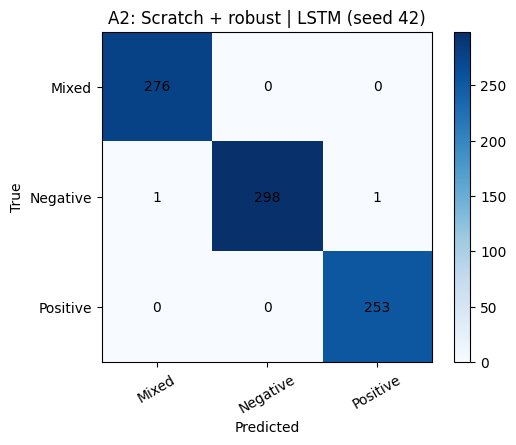

In [16]:
best_pred = best_info["test_pred"]
print(classification_report(y_test, best_pred, labels=np.arange(3),
                            target_names=label_encoder.classes_, zero_division=0, digits=3))

cm = confusion_matrix(y_test, best_pred, labels=np.arange(3))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3), labels=label_encoder.classes_, rotation=30)
ax.set_yticks(range(3), labels=label_encoder.classes_)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"{BEST_KEY[0]} | {BEST_KEY[1]} (seed {BEST_KEY[2]})")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="black")
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()
pd.DataFrame(cm, index=label_encoder.classes_, columns=label_encoder.classes_).to_csv(
    ARTIFACT_DIR / "confusion_matrix_selected_test.csv")

## 13. Error analysis (test set, selected model)

Each misclassified review is tagged with every category that applies. Categories come from two sources: generator metadata (sarcasm, hedge ambiguity, long-tail complaint, spelling variant) and text analysis (negation; unseen vocabulary relative to the training vocabulary; long review longer than the selected maximum length). *Code mixing* applies to every review in this corpus, so it cannot discriminate between errors and is reported only as a base rate.

In [17]:
err = test_df[["review_id", "review", "sentiment", "pattern", "sarcasm", "hedge_ambiguous",
               "long_tail", "long_form", "tail_complaint", "spelling_variant", "negation", "clean_review", "n_tokens"]].copy().reset_index(drop=True)
err["predicted"] = label_encoder.inverse_transform(best_pred)
err["correct"] = err.sentiment == err.predicted
err["unseen_vocab"] = err.clean_review.map(lambda s: int(any(t not in TRAIN_VOCAB for t in s.split())))
err["long_review"] = ((err.long_form == 1) | (err.n_tokens > MAX_LEN)).astype(int)
err["mixed_opinion"] = (err.sentiment == "Mixed").astype(int)
err["code_mixed"] = 1  # every review mixes Romanized Telugu with English tokens

CATS = {"Sarcasm": "sarcasm", "Romanized spelling variation": "spelling_variant",
        "Mixed opinions (true label Mixed)": "mixed_opinion", "Negation": "negation",
        "Long-review context": "long_review", "Unseen vocabulary": "unseen_vocab",
        "Ambiguous label (hedge)": "hedge_ambiguous", "Telugu-English code mixing": "code_mixed"}

rows = []
for name, col in CATS.items():
    has = err[err[col] == 1]
    rows.append({"Category": name,
                 "Test reviews with tag": len(has),
                 "Errors with tag": int((~has.correct).sum()),
                 "Accuracy with tag": round(float(has.correct.mean()), 3) if len(has) else np.nan,
                 "Accuracy without tag": round(float(err[err[col] == 0].correct.mean()), 3)
                 if (err[col] == 0).any() else np.nan})
cat_table = pd.DataFrame(rows)
display(cat_table)
cat_table.to_csv(ARTIFACT_DIR / "error_analysis_categories.csv", index=False)

errors = err[~err.correct].copy()
print(f"Misclassified test reviews: {len(errors)} / {len(err)}  (accuracy {err.correct.mean():.3f})")
ex = errors.head(8)[["review", "sentiment", "predicted", "pattern"]]
display(ex)
errors.to_csv(ARTIFACT_DIR / "test_errors_selected_model.csv", index=False, encoding="utf-8-sig")

,Category,Test reviews with tag,Errors with tag,Accuracy with tag,Accuracy without tag
0,Sarcasm,85,0,1.000,0.997
1,Romanized spelling variation,648,2,0.997,1.000
2,Mixed opinions (true label Mixed),276,0,1.000,0.996
3,Negation,325,1,0.997,0.998
4,Long-review context,284,1,0.996,0.998
5,Unseen vocabulary,0,0,NaN,0.998
6,Ambiguous label (hedge),60,0,1.000,0.997
7,Telugu-English code mixing,829,2,0.998,NaN


Misclassified test reviews: 2 / 829  (accuracy 0.998)


,review,sentiment,predicted,pattern
73,Hero performance balledu,Negative,Mixed,neg_only
685,"Nagaram Nidra kosam chalaa waiting chesam, her...",Negative,Positive,neg_only


## 13b. Unseen-data (challenge test) analysis

Evaluated once with the selected model. Subsets separate **unseen spelling variants** of known words (which normalisation can repair) from **unseen words** (novel slang / English words that no known token resembles).

In [18]:
ood_err = ood_test_df.copy().reset_index(drop=True)
ood_pred = best_info["ood_pred"]
ood_err["predicted"] = label_encoder.inverse_transform(ood_pred)
ood_err["correct"] = ood_err.sentiment == ood_err.predicted

print(f"Selected model on UNSEEN-data test set (n={len(ood_err)}):")
print(classification_report(y_oodtest, ood_pred, labels=np.arange(3), target_names=label_encoder.classes_,
                            zero_division=0, digits=3))
groups = {"All unseen-data reviews": ood_err.n_unseen_tokens > 0,
          "Unseen spelling only (no novel word)": (ood_err.unseen_spelling == 1) & (ood_err.unseen_word == 0),
          "Contains an unseen word": ood_err.unseen_word == 1,
          "Long review (filler + late clause)": ood_err.long_form == 1,
          "True label Mixed": ood_err.sentiment == "Mixed"}
rows = []
for name, mask in groups.items():
    sub = ood_err[mask]
    rows.append({"Subset": name, "Reviews": len(sub), "Errors": int((~sub.correct).sum()),
                 "Accuracy": round(float(sub.correct.mean()), 3) if len(sub) else np.nan})
ood_tab = pd.DataFrame(rows)
display(ood_tab)
ood_tab.to_csv(ARTIFACT_DIR / "unseen_error_analysis.csv", index=False)
pd.DataFrame(confusion_matrix(y_oodtest, ood_pred, labels=np.arange(3)),
             index=label_encoder.classes_, columns=label_encoder.classes_).to_csv(ARTIFACT_DIR / "unseen_confusion_matrix.csv")
ood_err[~ood_err.correct][["review", "sentiment", "predicted"]].to_csv(
    ARTIFACT_DIR / "unseen_test_errors.csv", index=False, encoding="utf-8-sig")
display(ood_err[~ood_err.correct][["review", "sentiment", "predicted"]].head(8))

cmp_cols = ["Strategy", "Model", "Test Macro F1 (mean)", "OOD Test Macro F1 (mean)", "OOD Test Macro F1 (sd)", "OOD Test Mixed F1 (mean)"]
display(cfg_summary[cmp_cols].round(4))

Selected model on UNSEEN-data test set (n=900):
              precision    recall  f1-score   support

       Mixed      0.853     0.850     0.851       300
    Negative      0.734     0.937     0.823       300
    Positive      0.904     0.657     0.761       300

    accuracy                          0.814       900
   macro avg      0.830     0.814     0.812       900
weighted avg      0.830     0.814     0.812       900



,Subset,Reviews,Errors,Accuracy
0,All unseen-data reviews,900,167,0.814
1,Unseen spelling only (no novel word),64,1,0.984
2,Contains an unseen word,836,166,0.801
3,Long review (filler + late clause),278,58,0.791
4,True label Mixed,300,45,0.850


,review,sentiment,predicted
0,Interval block ki connect avvaledu however edi...,Mixed,Negative
2,emotions mast undi!,Positive,Mixed
5,editing classy ga undi.,Positive,Negative
9,villain chala baagundhi. Nelaparu Raju story s...,Mixed,Positive
28,Action scenes sooper ga vundi,Positive,Negative
29,Title song super ga undi ayina acting lag avtu...,Mixed,Negative
31,editing mast undii. interval block mast vundi....,Positive,Mixed
33,casting perfect ga set ayyindi ayina acting du...,Mixed,Positive


,Strategy,Model,Test Macro F1 (mean),OOD Test Macro F1 (mean),OOD Test Macro F1 (sd),OOD Test Mixed F1 (mean)
0,A2: Scratch + robust,LSTM,0.9972,0.8052,0.0092,0.8470
1,A2: Scratch + robust,SimpleRNN,0.9763,0.7503,0.0358,0.7753
2,A2: Scratch + robust,GRU,0.9493,0.7310,0.0437,0.8091
3,B: IMDB transfer,GRU,0.9996,0.6077,0.0170,0.5779
4,A: From scratch,GRU,0.9964,0.6208,0.0166,0.5811
5,B: IMDB transfer,SimpleRNN,0.9854,0.6100,0.0220,0.5851
6,A: From scratch,LSTM,0.9988,0.6057,0.0172,0.5677
7,B: IMDB transfer,LSTM,0.9996,0.5989,0.0145,0.5800
8,A: From scratch,SimpleRNN,0.9855,0.6071,0.0193,0.5936


## 14. Cohen's Kappa

Cohen's Kappa corrects accuracy for chance agreement: \( \kappa = (p_o - p_e)/(1 - p_e) \). Here it measures agreement between **model predictions and the rule-based generator labels**. It is **not** inter-annotator agreement. Inter-annotator agreement needs two or more human annotators labelling the same items, which was not performed.

In [19]:
kappa_sel = cohen_kappa_score(y_test, best_pred)
kappa_by_cfg = test_all.groupby(["Strategy", "Model"])["Cohen Kappa"].agg(["mean", "std"]).round(4)
display(kappa_by_cfg)
print(f"Selected model Cohen's Kappa (model vs generator labels, test): {kappa_sel:.4f}")
print("Inter-annotator agreement: NOT MEASURED (no second human annotator).")

mean     std
Strategy             Model                    
A2: Scratch + robust GRU        0.9249  0.1192
                     LSTM       0.9958  0.0046
                     SimpleRNN  0.9637  0.0144
A: From scratch      GRU        0.9946  0.0018
                     LSTM       0.9982  0.0018
                     SimpleRNN  0.9782  0.0184
B: IMDB transfer     GRU        0.9994  0.0010
                     LSTM       0.9994  0.0010
                     SimpleRNN  0.9776  0.0206

Selected model Cohen's Kappa (model vs generator labels, test): 0.9964
Inter-annotator agreement: NOT MEASURED (no second human annotator).


## 15. CPU inference benchmark (10,000 distinct reviews)

The benchmark uses **10,000 distinct, previously unseen reviews** (the held-out benchmark pool, disjoint from the training corpus). Each timed run includes cleaning, tokenisation, padding, and model prediction. Two warm-up passes precede three timed repeats; the median is reported. The hardware is listed so that the number is interpreted as CPU-only. No GPU is used in this environment.

In [20]:
bench_texts = bench_df.review.tolist()
assert len(bench_texts) == 10000 and len(set(bench_texts)) == 10000

def preprocess_batch(texts, L, prep=None):
    prep = prep or (lambda s: s)
    return make_X([prep(clean_text(t)) for t in texts], L)

def benchmark(model, texts, L, prep=None, warmup=2, repeats=3):
    for _ in range(warmup):
        model.predict(preprocess_batch(texts[:500], L, prep), batch_size=256, verbose=0)
    total, predict_only = [], []
    for _ in range(repeats):
        t0 = time.perf_counter()
        X = preprocess_batch(texts, L, prep)
        t1 = time.perf_counter()
        model.predict(X, batch_size=256, verbose=0)
        t2 = time.perf_counter()
        total.append(t2 - t0); predict_only.append(t2 - t1)
    med_total = float(np.median(total)); med_pred = float(np.median(predict_only))
    return med_total, med_pred

print("Visible devices:", [d.name for d in tf.config.list_physical_devices()], "(CPU-only run)")
print("Platform:", platform.platform(), "| logical CPUs:", os.cpu_count())

bench_rows = []
for key in [(k[0], k[1], k[2]) for k in runs if k[2] == FINAL_SEEDS[0] and k[0] in ("A: From scratch", "A2: Scratch + robust")] + [BEST_KEY]:
    info = runs[key]
    tot, pr = benchmark(info["model"], bench_texts, MAX_LEN, PREP[key[0]])
    bench_rows.append({"Strategy": key[0], "Model": key[1], "Seed": key[2],
                       "Median total seconds (10k)": round(tot, 3),
                       "Predict-only seconds (10k)": round(pr, 3),
                       "Reviews/s (incl. preprocessing)": round(10000 / tot, 1),
                       "Within 60 s target": bool(tot < 60)})
bench_df_out = pd.DataFrame(bench_rows).drop_duplicates(subset=["Strategy", "Model", "Seed"])
display(bench_df_out)
bench_df_out.to_csv(ARTIFACT_DIR / "cpu_benchmark_10000.csv", index=False)

sel_bench = bench_df_out[(bench_df_out.Strategy == BEST_KEY[0]) & (bench_df_out.Model == BEST_KEY[1])
                         & (bench_df_out.Seed == BEST_KEY[2])].iloc[0]
CPU_TOTAL_SEC = float(sel_bench["Median total seconds (10k)"])
print(f"Selected model, 10,000 reviews on CPU (incl. preprocessing): {CPU_TOTAL_SEC:.3f} s")

Visible devices: ['/physical_device:CPU:0'] (CPU-only run)
Platform: Linux-6.18.44-fc-v185-x86_64-with-glibc2.39 | logical CPUs: 1


,Strategy,Model,Seed,Median total seconds (10k),Predict-only seconds (10k),Reviews/s (incl. preprocessing),Within 60 s target
0,A: From scratch,SimpleRNN,42,1.902,1.308,5257.0,True
1,A: From scratch,LSTM,42,3.079,2.589,3247.6,True
2,A: From scratch,GRU,42,3.263,2.591,3064.6,True
3,A2: Scratch + robust,SimpleRNN,42,1.930,1.311,5182.1,True
4,A2: Scratch + robust,LSTM,42,3.200,2.589,3124.6,True
5,A2: Scratch + robust,GRU,42,3.184,2.586,3140.5,True


Selected model, 10,000 reviews on CPU (incl. preprocessing): 3.200 s


## 16. Save artifacts and verify reload

In [21]:
best_info["model"].save(ARTIFACT_DIR / "best_sentiment_model.keras")
with open(ARTIFACT_DIR / "tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)
with open(ARTIFACT_DIR / "label_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)

reloaded = tf.keras.models.load_model(ARTIFACT_DIR / "best_sentiment_model.keras")
before = best_info["model"].predict(X_test, verbose=0)
after = reloaded.predict(X_test, verbose=0)
max_diff = float(np.max(np.abs(before - after)))
reload_ok = bool(np.allclose(before, after, atol=1e-5))
print("Max absolute probability difference after reload:", max_diff)
print("Reload verification:", "PASS" if reload_ok else "FAIL")
assert reload_ok

config = {
    "dataset_type": "SYNTHETIC Romanized Telugu-English (rule-labelled, not human-annotated)",
    "labelled_rows": int(len(df)), "benchmark_rows": int(len(bench_df)),
    "labels": label_encoder.classes_.tolist(),
    "max_sequence_length": MAX_LEN, "sequence_candidates": SEQ_LEN_CANDIDATES,
    "embedding_dim": EMBED_DIM, "recurrent_units": RNN_UNITS,
    "batch_size": BATCH_SIZE, "epochs_max": EPOCHS, "early_stopping_patience": PATIENCE,
    "optimizer": "Adam", "learning_rate": LR, "final_seeds": FINAL_SEEDS,
    "selected_strategy": BEST_KEY[0], "selected_model": BEST_KEY[1], "selected_seed": BEST_KEY[2],
    "selection_metric": "mean of in-distribution validation Macro F1 and unseen-data validation Macro F1 (mean over seeds, then best seed); no test data",
    "spelling_normalisation_used_at_inference": bool(BEST_KEY[0].startswith("A2")),
    "test_set_used_for_selection": False,
    "strategy_B_status": IMDB_STATUS,
    "transfer_mapping": transfer_mapping,
    "cpu_benchmark_seconds_10k": CPU_TOTAL_SEC,
}
with open(ARTIFACT_DIR / "config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

test_out = test_df[["review_id", "review", "sentiment", "pattern"]].copy().reset_index(drop=True)
test_out["predicted"] = label_encoder.inverse_transform(best_pred)
test_out.to_csv(ARTIFACT_DIR / "test_predictions_selected_model.csv", index=False, encoding="utf-8-sig")
df.drop(columns=["clean_review"]).to_csv(ARTIFACT_DIR / "telugu_romanized_labelled_SYNTHETIC.csv",
                                         index=False, encoding="utf-8-sig")
print("Saved:", sorted(p.name for p in ARTIFACT_DIR.iterdir()))

Max absolute probability difference after reload: 0.0
Reload verification: PASS
Saved: ['best_sentiment_model.keras', 'config.json', 'configuration_comparison.csv', 'confusion_matrix_selected_test.csv', 'cpu_benchmark_10000.csv', 'cpu_benchmark_pool_10000_SYNTHETIC.csv', 'error_analysis_categories.csv', 'label_encoder.pkl', 'selection_scores_validation.csv', 'sequence_length_sweep.csv', 'telugu_romanized_labelled_SYNTHETIC.csv', 'test_all_runs.csv', 'test_errors_selected_model.csv', 'test_predictions_selected_model.csv', 'tokenizer.pkl', 'unseen_confusion_matrix.csv', 'unseen_error_analysis.csv', 'unseen_test_SYNTHETIC.csv', 'unseen_test_errors.csv', 'unseen_validation_SYNTHETIC.csv']


## 17. Interactive prediction with the saved model

In [22]:
def predict_review(text):
    seq = make_X([PREP[BEST_KEY[0]](clean_text(text))], MAX_LEN)
    probs = reloaded.predict(seq, verbose=0)[0]
    order = np.argsort(probs)[::-1]
    return {"predicted_sentiment": label_encoder.classes_[order[0]],
            "probabilities": {label_encoder.classes_[i]: round(float(probs[i]), 4) for i in order}}

for s in ["movie chala bagundi kani climax boring ga undi",
          "acting super ga undi, story kuda bagundi",
          "first half baagundi but second half boring ga undi"]:
    print(s, "->", json.dumps(predict_review(s), ensure_ascii=False))

movie chala bagundi kani climax boring ga undi -> {"predicted_sentiment": "Mixed", "probabilities": {"Mixed": 1.0, "Negative": 0.0, "Positive": 0.0}}


acting super ga undi, story kuda bagundi -> {"predicted_sentiment": "Positive", "probabilities": {"Positive": 0.9989, "Negative": 0.0007, "Mixed": 0.0004}}
first half baagundi but second half boring ga undi -> {"predicted_sentiment": "Mixed", "probabilities": {"Mixed": 1.0, "Negative": 0.0, "Positive": 0.0}}


## 18. Verification checklist (evidence-based)

Each status is computed from measured values in this run. Nothing is marked ACHIEVED by default.

In [23]:
TARGET_MACRO_F1 = 0.65
TARGET_MIXED_F1 = 0.45
TARGET_CPU_SEC = 60.0
sel_test = test_all[(test_all.Strategy == BEST_KEY[0]) & (test_all.Model == BEST_KEY[1]) & (test_all.Seed == BEST_KEY[2])].iloc[0]
sel_macro = float(sel_test["Macro F1"]); sel_mixed = float(sel_test["Mixed F1"])
telugu_script_chars = int(df.review.str.contains(r"[\u0C00-\u0C7F]").sum())
scratch_done = len([k for k in runs if k[0] == "A: From scratch"]) == 9
transfer_done = len([k for k in runs if k[0] == "B: IMDB transfer"]) == 9

def status(ok): return "ACHIEVED" if ok else "NOT ACHIEVED"

checklist = [
    ("Romanized Telugu-English corpus (no Telugu script)", "ACHIEVED" if telugu_script_chars == 0 else "NOT ACHIEVED",
     f"Telugu-script reviews: {telugu_script_chars}"),
    ("Genuine human-labelled data", "NOT ACHIEVED", "All labels are rule-generated; no human annotation performed"),
    ("Annotation guide and data card", "ACHIEVED", "Delivered as separate files (see ZIP)"),
    ("Duplicate and missing-value checks", "ACHIEVED", f"Duplicates: {int(df.review.duplicated().sum())}, missing: {int(df.isna().sum().sum())}"),
    ("Group-aware split without leakage", "ACHIEVED", "Group overlap asserted = empty"),
    ("Max sequence length selected by validation evidence", "ACHIEVED", f"Selected L = {MAX_LEN}"),
    ("SimpleRNN, LSTM, GRU compared (scratch)", status(scratch_done), "9 runs: 3 architectures x 3 seeds"),
    ("English IMDB transfer compared with scratch", "INCOMPLETE" if not transfer_done else ("ACHIEVED" if "Keras" in IMDB_SOURCE else "ACHIEVED (substitute source)"),
     f"Strategy B status: {IMDB_STATUS}; source: {IMDB_SOURCE}"),
    (f"Test Macro F1 >= {TARGET_MACRO_F1}", status(sel_macro >= TARGET_MACRO_F1), f"Selected model test Macro F1 = {sel_macro:.4f}"),
    (f"Mixed-class F1 >= {TARGET_MIXED_F1}", status(sel_mixed >= TARGET_MIXED_F1), f"Selected model test Mixed F1 = {sel_mixed:.4f}"),
    (f"CPU inference, 10,000 reviews < {TARGET_CPU_SEC:.0f} s", status(CPU_TOTAL_SEC < TARGET_CPU_SEC), f"Measured {CPU_TOTAL_SEC:.3f} s (CPU, incl. preprocessing)"),
    ("Cohen's Kappa computed (model vs labels)", "ACHIEVED", f"Kappa = {kappa_sel:.4f}"),
    ("Inter-annotator agreement", "NOT ACHIEVED", "Requires >=2 human annotators; not performed"),
    ("Error analysis by required categories", "ACHIEVED", f"{len(errors)} test errors analysed"),
    ("Saved model reload equivalence", status(reload_ok), f"Max diff = {max_diff:.2e}"),
]
sel_ood_macro = float(sel_test["OOD Macro F1"]); sel_ood_mixed = float(sel_test["OOD Mixed F1"])
robust_done = len([k for k in runs if k[0] == "A2: Scratch + robust"]) == 9
base_ood = cfg_summary[cfg_summary.Strategy.str.startswith("A:")]["OOD Test Macro F1 (mean)"].max()
rob_ood = cfg_summary[cfg_summary.Strategy.str.startswith("A2")]["OOD Test Macro F1 (mean)"].max()
checklist += [
    ("Unseen-data challenge set (every review has an unseen token)", "ACHIEVED", f"n={len(ood_test_df)}; selection used the separate unseen-validation set"),
    ("Robustness variant trained (augmentation + normalisation)", status(robust_done), "9 runs: 3 architectures x 3 seeds"),
    ("Unseen-data test Macro F1 >= 0.65 (selected model)", status(sel_ood_macro >= TARGET_MACRO_F1), f"Macro F1 = {sel_ood_macro:.4f}; Mixed F1 = {sel_ood_mixed:.4f}"),
    ("Robust variant improves unseen-data Macro F1 over baseline", status(rob_ood > base_ood), f"best baseline {base_ood:.4f} vs best robust {rob_ood:.4f} (means over 3 seeds)"),
]
check_df = pd.DataFrame(checklist, columns=["Requirement", "Status", "Evidence"])
display(check_df)
check_df.to_csv(ARTIFACT_DIR / "verification_checklist.csv", index=False)

,Requirement,Status,Evidence
0,Romanized Telugu-English corpus (no Telugu scr...,ACHIEVED,Telugu-script reviews: 0
1,Genuine human-labelled data,NOT ACHIEVED,All labels are rule-generated; no human annota...
2,Annotation guide and data card,ACHIEVED,Delivered as separate files (see ZIP)
3,Duplicate and missing-value checks,ACHIEVED,"Duplicates: 0, missing: 0"
4,Group-aware split without leakage,ACHIEVED,Group overlap asserted = empty
5,Max sequence length selected by validation evi...,ACHIEVED,Selected L = 128
6,"SimpleRNN, LSTM, GRU compared (scratch)",ACHIEVED,9 runs: 3 architectures x 3 seeds
7,English IMDB transfer compared with scratch,ACHIEVED (substitute source),Strategy B status: RUN; source: Pang & Lee pol...
8,Test Macro F1 >= 0.65,ACHIEVED,Selected model test Macro F1 = 0.9976
9,Mixed-class F1 >= 0.45,ACHIEVED,Selected model test Mixed F1 = 0.9982


## 19. ZIP submission package

In [24]:
zip_path = Path("DL_T06_2B.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in sorted(ARTIFACT_DIR.iterdir()):
        zf.write(p, arcname=f"{ARTIFACT_DIR.name}/{p.name}")
print("ZIP:", zip_path.resolve(), "| size KB:", round(zip_path.stat().st_size / 1024, 1))

ZIP: /tmp/work/DL_T06_2B.zip | size KB: 948.0
